# 02: Regression: predicting the six scheme scores

**Goal:** for each scheme score, find the simplest model that comes close to the best achievable score, then save it for the DSS.

**Plan (from the decisions log in `01_eda.ipynb`):**
- **Targets:** primary `mgnrega`, `pmksy` and `soil_health_card`; side experiments `jjm`, `pmfby` and `pm_kisan`.
- **Features** (9, built by `backend/services/ml_features.py`): `land_area_ha`, `small_holding`, `is_ifr`, `is_cfr` (one-hot `claim_type`, CR as reference), `soil_ph`, `ph_band`, `oc_pct`, `groundwater_stress_pct`, `rainfall_mm_avg`. lat/lon/elevation/clay are left out.
- **Split:** one test set of whole `spatial_block`s (20%, seed 42), touched once. Tuning uses `GroupKFold(5)` on `spatial_block` inside the training split.
- **Models:** simple linear → multiple linear → decision tree → SVR → random forest. Each is compared with three baselines and the R² ceiling.
- **Selection rule:** the **simplest** model whose CV R² is within 0.02 of the best.

> **Honesty note.** The labels come from `backend/services/scheme_rules.py` plus Gaussian noise. They are not real scheme allocations or eligibility decisions. A model scoring near the **R² ceiling** has recovered those rules. That is the best possible result here, and it says nothing about real-world accuracy, because no real outcome data exists yet. A score *above* the ceiling would mean leakage.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fra_ml.py").exists() or (p / "ml" / "fra_ml.py").exists())
ML = ML if (ML / "fra_ml.py").exists() else ML / "ml"
sys.path.insert(0, str(ML))
from fra_ml import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4.5)})
pd.set_option("display.width", 200, "display.max_columns", 40)

df = load_data()
train, test = split(df)
print(f"train {len(train)} rows / {train.spatial_block.nunique()} blocks | test {len(test)} rows / {test.spatial_block.nunique()} blocks")
print("test rows per district:", test.district.value_counts().to_dict())

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, validation_curve
import joblib, sklearn

ORDER = ["simple linear", "multiple linear", "decision tree", "SVR (RBF)", "random forest"]   # simplest first
rows, test_preds, fitted, tuned_params = [], {}, {}, {}

train 1211 rows / 92 blocks | test 329 rows / 23 blocks
test rows per district: {'Adilabad': 80, 'Shivpuri': 74, 'West Tripura': 72, 'Chhindwara': 32, 'Kandhamal': 31, 'Warangal': 29, 'Koraput': 11}


## 1. Baselines
Any model has to beat these to be worth having:
- **training mean:** predict the same number for every plot (R² ≈ 0 by definition).
- **per-district mean:** "which district is it in?" From EDA F1, this alone is most of jjm, pmksy and pmfby.
- **per-claim_type mean:** "is it IFR, CFR or CR?" This alone is almost all of pm_kisan.

In [2]:
for t in TARGETS:
    rows += baseline_rows(train, test, t)
base = pd.DataFrame(rows).pivot(index="model", columns="target", values="cv_R2").rename(columns=SHORT)
base.loc["R² ceiling"] = [CEILING[t] for t in [k + "_score" for k in base.columns]]
base.round(3)

target,jjm,mgnrega,pm_kisan,pmfby,pmksy,soil_health_card
model,,,,,,
baseline: per-claim_type mean,-0.057,0.202,0.975,-0.042,-0.052,-0.034
baseline: per-district mean,0.834,0.114,-0.020,0.587,0.868,0.505
baseline: training mean,-0.053,-0.007,-0.006,-0.039,-0.055,-0.028
R² ceiling,0.846,0.583,0.975,0.627,0.917,0.922


## 2. Simple linear regression (one feature)
$\hat y = b_0 + b_1 x$. The **cost (loss)** being minimised is the mean squared error, $\frac1n\sum (y_i-\hat y_i)^2$, which has a closed-form least-squares solution. For each target we pick the single feature most correlated with it **on the training split only**. Choosing it on all the data would leak information from the test set.

In [3]:
from backend.services.ml_features import add_engineered_features, MODEL_FEATURES
eng_train = add_engineered_features(X_of(train))
best_single = {}
for t in TARGETS:
    corr = eng_train[MODEL_FEATURES].corrwith(train[t]).abs()
    best_single[t] = corr.idxmax()
    pipe = make_pipe(LinearRegression(), features=[best_single[t]])
    row, test_preds[(t, "simple linear")] = evaluate(pipe, train, test, t, "simple linear")
    row["params"] = f"x = {best_single[t]}"
    rows.append(row); fitted[(t, "simple linear")] = pipe
pd.Series(best_single, name="chosen single feature")

pm_kisan_score                            is_ifr
mgnrega_score                             is_ifr
jjm_score                        rainfall_mm_avg
pmfby_score                      rainfall_mm_avg
pmksy_score               groundwater_stress_pct
soil_health_card_score                   ph_band
Name: chosen single feature, dtype: str

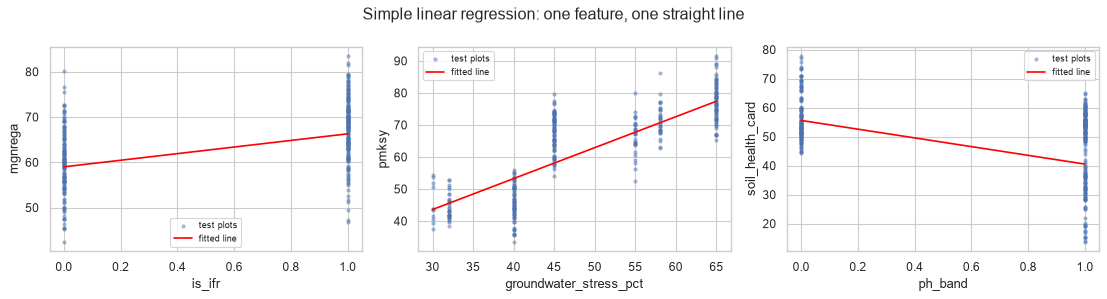

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t in zip(axes, PRIMARY):
    x = add_engineered_features(X_of(test))[best_single[t]]
    ax.scatter(x, test[t], s=8, alpha=0.4, label="test plots")
    xs = np.linspace(x.min(), x.max(), 50)
    line = fitted[(t, "simple linear")].named_steps["model"]
    sc = fitted[(t, "simple linear")].named_steps["select"].named_transformers_["num"]
    ax.plot(xs, line.predict(sc.transform(pd.DataFrame({best_single[t]: xs}))), color="red", label="fitted line")
    ax.set_xlabel(best_single[t]); ax.set_ylabel(SHORT[t]); ax.legend(fontsize=8)
fig.suptitle("Simple linear regression: one feature, one straight line"); plt.tight_layout(); plt.show()

## 3. Multiple linear regression
$\hat y = b_0 + \sum_j b_j x_j$ over all 9 features (standardized, so the coefficients are comparable). It can only add up straight-line effects, so it cannot represent the rules' **steps** (pH bands) or **interactions** (Scheduled Area × IFR).

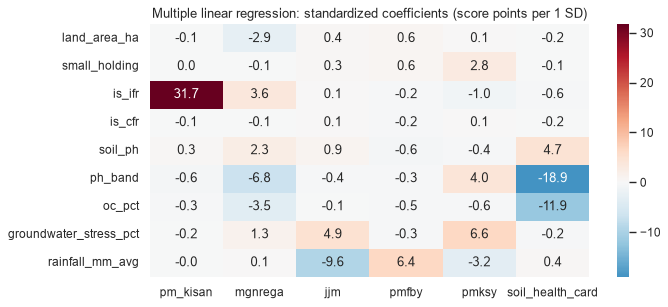

In [5]:
coefs = {}
for t in TARGETS:
    pipe = make_pipe(LinearRegression())
    row, test_preds[(t, "multiple linear")] = evaluate(pipe, train, test, t, "multiple linear")
    row["params"] = "OLS, 9 standardized features"
    rows.append(row); fitted[(t, "multiple linear")] = pipe
    coefs[SHORT[t]] = pd.Series(pipe.named_steps["model"].coef_, index=MODEL_FEATURES)
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(pd.DataFrame(coefs), annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Multiple linear regression: standardized coefficients (score points per 1 SD)"); plt.tight_layout(); plt.show()

Coefficients on correlated features (`groundwater_stress_pct` and `rainfall_mm_avg`, which are two district constants) can take odd signs and sizes. Multicollinearity splits the effect between them, so read the coefficients together, not one by one.

## 4. Decision tree regression, overfitting and the bias–variance trade-off
A tree splits the data with yes/no questions ("is `oc_pct` < 1.5?") and predicts the mean of each leaf, so it can represent the rules' steps. **Depth** controls complexity:
- **too shallow → underfitting (high bias):** it can't express the rule.
- **too deep → overfitting (high variance):** it memorises the training noise, and train R² climbs while CV R² falls.

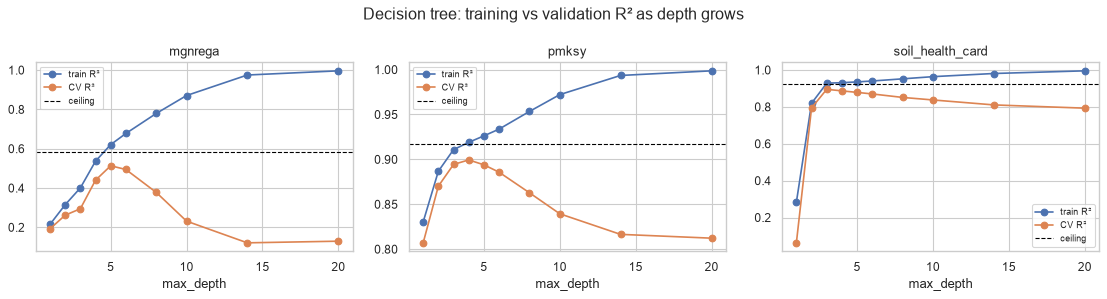

In [6]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 14, 20]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t in zip(axes, PRIMARY):
    tr_s, cv_s = validation_curve(make_pipe(DecisionTreeRegressor(random_state=SEED)), X_of(train), train[t],
                                  param_name="model__max_depth", param_range=depths, cv=group_cv(),
                                  groups=train.spatial_block, scoring="r2")
    ax.plot(depths, tr_s.mean(1), "o-", label="train R²"); ax.plot(depths, cv_s.mean(1), "o-", label="CV R²")
    ax.axhline(CEILING[t], ls="--", color="black", lw=1, label="ceiling")
    ax.set_xlabel("max_depth"); ax.set_title(SHORT[t]); ax.legend(fontsize=8)
fig.suptitle("Decision tree: training vs validation R² as depth grows"); plt.tight_layout(); plt.show()

Train R² keeps climbing toward 1.0, which is the tree memorising noise. CV R² peaks and then sinks. The gap between the curves is **variance**, and the CV curve's peak is the sweet spot. Notice that train R² *passes* the ceiling: a model can fit the training noise, but it can never predict new noise.

In [7]:
GRIDS = {
    "decision tree": (DecisionTreeRegressor(random_state=SEED),
                      {"model__max_depth": [3, 4, 5, 6, 8, 10], "model__min_samples_leaf": [1, 5, 10, 20]}),
    "SVR (RBF)": (SVR(kernel="rbf"),
                  {"model__C": [3, 10, 30, 100], "model__epsilon": [1.0, 3.0], "model__gamma": ["scale", 0.05, 0.2]}),
    "random forest": (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [None, 8], "model__min_samples_leaf": [1, 5, 10], "model__max_features": [1.0, 0.5]}),
}

def tune_and_eval(name):
    est, grid = GRIDS[name]
    for t in TARGETS:
        gs = GridSearchCV(make_pipe(clone(est)), grid, cv=group_cv(), scoring="r2", n_jobs=-1)
        gs.fit(X_of(train), train[t], groups=train.spatial_block)
        pipe = clone(gs.best_estimator_)
        row, test_preds[(t, name)] = evaluate(pipe, train, test, t, name)
        tuned_params[(t, name)] = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
        row["params"] = json.dumps(tuned_params[(t, name)])
        rows.append(row); fitted[(t, name)] = pipe
    return pd.Series({SHORT[t]: row_["params"] for t in TARGETS for row_ in rows if row_["target"] == t and row_["model"] == name})

tune_and_eval("decision tree")

pm_kisan            {"max_depth": 3, "min_samples_leaf": 20}
mgnrega             {"max_depth": 6, "min_samples_leaf": 20}
jjm                 {"max_depth": 4, "min_samples_leaf": 10}
pmfby                {"max_depth": 3, "min_samples_leaf": 5}
pmksy               {"max_depth": 4, "min_samples_leaf": 20}
soil_health_card    {"max_depth": 3, "min_samples_leaf": 10}
dtype: str

**Tuning honesty:** the grid search picks parameters by GroupKFold CV, and the CV score reported later reuses the same folds, so it is slightly optimistic. The **test** column is the unbiased check: it was never used for any choice.

## 5. Support Vector Regression (RBF kernel)
SVR fits a function that keeps most training points inside an **ε-tube** (errors smaller than ε cost nothing) while staying as flat as possible. The **RBF kernel** lets it bend: it compares plots by similarity $e^{-\gamma\|x-x'\|^2}$.
- **C** trades flatness against errors (large C → fits harder → risk of overfitting).
- **γ** sets how local the bends are.

Scaling matters here, and the pipeline's StandardScaler handles it.

In [8]:
tune_and_eval("SVR (RBF)")

pm_kisan                {"C": 30, "epsilon": 3.0, "gamma": 0.05}
mgnrega                 {"C": 10, "epsilon": 1.0, "gamma": 0.05}
jjm                     {"C": 10, "epsilon": 3.0, "gamma": 0.05}
pmfby                    {"C": 3, "epsilon": 3.0, "gamma": 0.05}
pmksy                  {"C": 100, "epsilon": 3.0, "gamma": 0.05}
soil_health_card    {"C": 100, "epsilon": 3.0, "gamma": "scale"}
dtype: str

## 6. Random forest
A forest is many deep trees, each trained on a **bootstrap sample** (rows drawn with replacement) and a random subset of features, with their predictions averaged. Averaging cancels much of a single tree's variance without adding much bias. This is the bootstrapping idea from Unit 3 put to work.

In [9]:
tune_and_eval("random forest")

pm_kisan            {"max_depth": 8, "max_features": 1.0, "min_sam...
mgnrega             {"max_depth": 8, "max_features": 1.0, "min_sam...
jjm                 {"max_depth": 8, "max_features": 0.5, "min_sam...
pmfby               {"max_depth": 8, "max_features": 0.5, "min_sam...
pmksy               {"max_depth": 8, "max_features": 0.5, "min_sam...
soil_health_card    {"max_depth": 8, "max_features": 1.0, "min_sam...
dtype: str

## 7. Comparison against baselines and ceilings

**Ceiling vs oracle: a lesson from this run.** The first version of this notebook stopped here, because `jjm` and `pmfby` scored *above* their published ceilings on the test set (for example pmfby test R² 0.677 vs ceiling 0.627). Stop and investigate is the rule, so we did. The published ceiling is a **population** number: signal variance ÷ (signal + noise variance) over the whole dataset. This particular test split happens to hold many West Tripura and Shivpuri plots, the two climate extremes, so its signal variance is larger and more R² is achievable on it. The fix is to measure the best achievable R² **on the same rows**: score them with the noiseless rule from `scheme_rules.py` (the *oracle*). On the test split the oracle gets jjm 0.877 and pmfby 0.681, just above the models. CV R² never crossed the ceiling. So this was **not leakage**, and the guard now compares each score with the oracle R² on the same rows (`cv_oracle_R2`, `test_oracle_R2`). The published ceiling stays in the table for reference.

In [10]:
cmp = pd.DataFrame(rows)
assert not cmp.leak_flag.any(), cmp[cmp.leak_flag]   # stop here if anything beats the oracle on the same rows by > 0.02
print("leak flags:", int(cmp.leak_flag.sum()))
view = cmp[["target", "model", "train_R2", "cv_R2", "cv_oracle_R2", "test_R2", "test_R2_ci_low", "test_R2_ci_high", "test_oracle_R2", "test_MAE", "test_RMSE", "ceiling"]].copy()
view["target"] = view.target.map(SHORT)
view.round(3).set_index(["target", "model"])

leak flags: 0


train_R2  cv_R2  cv_oracle_R2  test_R2  test_R2_ci_low  test_R2_ci_high  test_oracle_R2  test_MAE  test_RMSE  ceiling
target           model                                                                                                                                               
pm_kisan         baseline: training mean           0.000 -0.006         0.975   -0.005          -0.031           -0.000           0.977    31.346     31.790    0.975
                 baseline: per-district mean       0.006 -0.020         0.975   -0.008          -0.043            0.015           0.977    31.274     31.832    0.975
                 baseline: per-claim_type mean     0.976  0.975         0.975    0.977           0.972            0.981           0.977     3.788      4.832    0.975
mgnrega          baseline: training mean           0.000 -0.007         0.602   -0.030          -0.085           -0.005           0.629     6.493      7.971    0.583
                 baseline: per-district mean       0.125  0.114         0.602    0.098           0.015            0.167           0.629     6.082      7.458    0.583
                 baseline: per-claim_type mean     0.215  0.202         0.602    0.206           0.119            0.278           0.629     5.564      7.000    0.583
jjm              baseline: training mean           0.000 -0.053         0.835   -0.002          -0.022           -0.000           0.877    14.060     16.553    0.846
                 baseline: per-district mean       0.835  0.834         0.835    0.877           0.851            0.896           0.877     4.697      5.809    0.846
                 baseline: per-claim_type mean     0.001 -0.057         0.835   -0.002          -0.023            0.003           0.877    14.065     16.552    0.846
pmfby            baseline: training mean           0.000 -0.039         0.589   -0.000          -0.017           -0.000           0.681     8.878     10.803    0.627
                 baseline: per-district mean       0.593  0.587         0.589    0.681           0.625            0.727           0.681     5.055      6.100    0.627
                 baseline: per-claim_type mean     0.000 -0.042         0.589    0.000          -0.016            0.001           0.681     8.878     10.800    0.627
pmksy            baseline: training mean           0.000 -0.055         0.919   -0.066          -0.134           -0.023           0.896    12.936     14.434    0.917
                 baseline: per-district mean       0.869  0.868         0.919    0.840           0.814            0.864           0.896     4.502      5.585    0.917
                 baseline: per-claim_type mean     0.007 -0.052         0.919   -0.061          -0.134           -0.012           0.896    12.922     14.401    0.917
soil_health_card baseline: training mean           0.000 -0.028         0.928   -0.048          -0.119           -0.012           0.893    10.388     12.751    0.922
                 baseline: per-district mean       0.521  0.505         0.928    0.198           0.015            0.333           0.893     8.664     11.150    0.922
                 baseline: per-claim_type mean     0.002 -0.034         0.928   -0.050          -0.126           -0.009           0.893    10.422     12.761    0.922
pm_kisan         simple linear                     0.976  0.975         0.975    0.977           0.972            0.981           0.977     3.785      4.828    0.975
mgnrega          simple linear                     0.214  0.202         0.602    0.203           0.116            0.276           0.629     5.577      7.010    0.583
jjm              simple linear                     0.770  0.758         0.835    0.830           0.792            0.858           0.877     5.392      6.821    0.846
pmfby            simple linear                     0.589  0.588         0.589    0.681           0.626            0.729           0.681     5.048      6.100    0.627
pmksy            simple linear                     0.774  0.769 

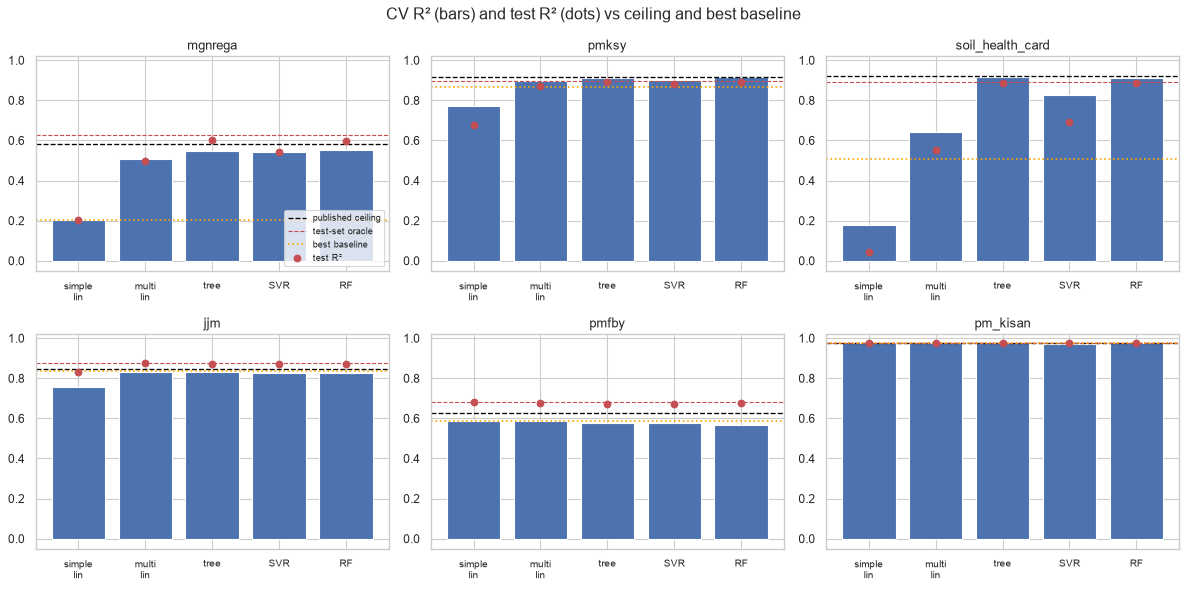

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=False)
models_only = [m for m in ORDER]
for ax, t in zip(axes.flat, PRIMARY + SIDE):
    sub = cmp[cmp.target == t].set_index("model")
    vals = sub.loc[models_only, "cv_R2"]
    ax.bar(range(len(vals)), vals, color="#4C72B0")
    ax.errorbar(range(len(vals)), sub.loc[models_only, "test_R2"], fmt="o", color="#C44E52", label="test R²")
    ax.axhline(CEILING[t], color="black", ls="--", lw=1.2, label="published ceiling")
    ax.axhline(sub.test_oracle_R2.iloc[0], color="#C44E52", ls="--", lw=1, label="test-set oracle")
    best_base = sub.loc[[m for m in sub.index if m.startswith("baseline")], "cv_R2"].max()
    ax.axhline(best_base, color="orange", ls=":", lw=1.5, label="best baseline")
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(["simple\nlin", "multi\nlin", "tree", "SVR", "RF"], fontsize=9)
    ax.set_title(SHORT[t]); ax.set_ylim(min(0, vals.min()) - 0.05, 1.02)
axes.flat[0].legend(fontsize=8, loc="lower right")
fig.suptitle("CV R² (bars) and test R² (dots) vs ceiling and best baseline"); plt.tight_layout(); plt.show()

## 8. Model selection: the simplest model within 0.02 R² of the best
For each target: take the best CV R² among the five models, then walk the list from simplest to most complex and pick the first one within 0.02 of it. A simpler model is easier to explain to an officer and less likely to break on new inputs.

In [12]:
chosen = {}
for t in TARGETS:
    sub = cmp[(cmp.target == t) & cmp.model.isin(ORDER)].set_index("model")
    best = sub.cv_R2.max()
    chosen[t] = next(m for m in ORDER if sub.loc[m, "cv_R2"] >= best - 0.02)
sel = pd.DataFrame({
    "chosen model": {SHORT[t]: chosen[t] for t in TARGETS},
    "best CV R²": {SHORT[t]: cmp[(cmp.target == t) & cmp.model.isin(ORDER)].cv_R2.max() for t in TARGETS},
    "chosen CV R²": {SHORT[t]: cmp.set_index(["target", "model"]).loc[(t, chosen[t]), "cv_R2"] for t in TARGETS},
    "chosen test R²": {SHORT[t]: cmp.set_index(["target", "model"]).loc[(t, chosen[t]), "test_R2"] for t in TARGETS},
    "test oracle R²": {SHORT[t]: cmp[cmp.target == t].test_oracle_R2.iloc[0] for t in TARGETS},
    "published ceiling": {SHORT[t]: CEILING[t] for t in TARGETS},
})
sel["test % of oracle"] = sel["chosen test R²"] / sel["test oracle R²"]
sel.round(3)

,chosen model,best CV R²,chosen CV R²,chosen test R²,test oracle R²,published ceiling,test % of oracle
pm_kisan,simple linear,0.975,0.975,0.977,0.977,0.975,1.000
mgnrega,decision tree,0.550,0.547,0.601,0.629,0.583,0.956
jjm,multiple linear,0.834,0.834,0.875,0.877,0.846,0.997
pmfby,simple linear,0.588,0.588,0.681,0.681,0.627,1.001
pmksy,multiple linear,0.915,0.896,0.872,0.896,0.917,0.973
soil_health_card,decision tree,0.917,0.917,0.888,0.893,0.922,0.994


## 9. Where the chosen models go wrong

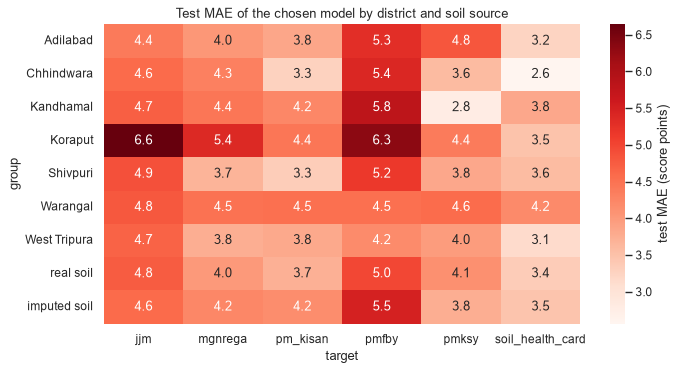

test rows per group: {'Adilabad': 80, 'Shivpuri': 74, 'West Tripura': 72, 'Chhindwara': 32, 'Kandhamal': 31, 'Warangal': 29, 'Koraput': 11, 'real soil': 280, 'imputed soil': 49}


In [13]:
err = []
for t in TARGETS:
    e = np.abs(test[t] - test_preds[(t, chosen[t])])
    for d, v in e.groupby(test.district).mean().items():
        err.append({"target": SHORT[t], "group": d, "MAE": v})
    for flag, v in e.groupby(test.soil_imputed).mean().items():
        err.append({"target": SHORT[t], "group": "imputed soil" if flag else "real soil", "MAE": v})
err = pd.DataFrame(err).pivot(index="group", columns="target", values="MAE")
order = sorted(test.district.unique()) + ["real soil", "imputed soil"]
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(err.loc[order], annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "test MAE (score points)"})
ax.set_title("Test MAE of the chosen model by district and soil source"); plt.tight_layout(); plt.show()
print("test rows per group:", {**test.district.value_counts().to_dict(), "real soil": int((~test.soil_imputed).sum()), "imputed soil": int(test.soil_imputed.sum())})

Koraput has only 11 test rows, so treat its MAE as rough. With noise SD 4–6, a MAE around **3–5 points** is about as low as it can go: the remaining error is the label noise itself.

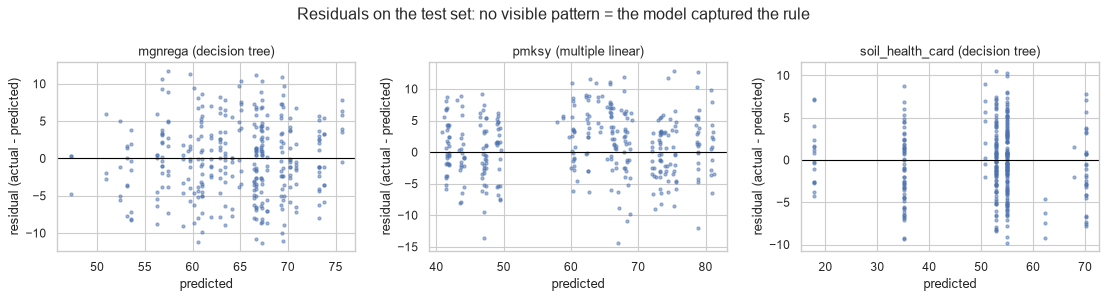

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t in zip(axes, PRIMARY):
    p = test_preds[(t, chosen[t])]
    ax.scatter(p, test[t] - p, s=8, alpha=0.5); ax.axhline(0, color="black", lw=1)
    ax.set_xlabel("predicted"); ax.set_ylabel("residual (actual - predicted)"); ax.set_title(f"{SHORT[t]} ({chosen[t]})")
fig.suptitle("Residuals on the test set: no visible pattern = the model captured the rule"); plt.tight_layout(); plt.show()

## 10. Robustness
1. **Without imputed rows:** retrain on real-soil training rows only, and test on real-soil test rows.
2. **Leave-one-district-out (LODO):** can the model score a district it has never seen? EDA predicted failure for jjm, pmfby and pmksy.
3. **Ablation:** add back lat/lon/elevation/clay and see whether they help or just add noise.

In [15]:
rob = []
real_tr, real_te = train[~train.soil_imputed], test[~test.soil_imputed]
for t in TARGETS:
    base_model = fitted[(t, chosen[t])]
    r_all = metrics(real_te[t], base_model.predict(X_of(real_te)))["R2"]
    m_real = clone(base_model).fit(X_of(real_tr), real_tr[t])
    r_real = metrics(real_te[t], m_real.predict(X_of(real_te)))["R2"]
    lodo = cross_val_predict(clone(base_model), X_of(df), df[t], cv=LeaveOneGroupOut(), groups=df.district)
    rob.append({"target": SHORT[t], "model": chosen[t],
                "test R² (real-soil rows, trained on all)": r_all,
                "test R² (real-soil rows, trained on real only)": r_real,
                "LODO pooled R²": r2_score(df[t], lodo),
                "group-CV R²": cmp.set_index(["target", "model"]).loc[(t, chosen[t]), "cv_R2"]})
rob = pd.DataFrame(rob).set_index("target")
print(f"real-soil rows: train {len(real_tr)}, test {len(real_te)}")
rob.round(3)

real-soil rows: train 801, test 280


,model,"test R² (real-soil rows, trained on all)","test R² (real-soil rows, trained on real only)",LODO pooled R²,group-CV R²
target,,,,,
pm_kisan,simple linear,0.978,0.978,0.976,0.975
mgnrega,decision tree,0.615,0.588,0.518,0.547
jjm,multiple linear,0.881,0.880,0.841,0.834
pmfby,simple linear,0.712,0.712,0.612,0.588
pmksy,multiple linear,0.859,0.860,0.674,0.896
soil_health_card,decision tree,0.894,0.898,0.909,0.917


In [16]:
from sklearn.metrics import r2_score
from backend.services.ml_features import ABLATION_EXTRA
abl = []
for t in TARGETS:
    est, grid = GRIDS["random forest"]
    params = tuned_params[(t, "random forest")]
    for label, extra in [("rule features", []), ("+ lat/lon/elev/clay", ABLATION_EXTRA)]:
        pipe = make_pipe(clone(est).set_params(**params), features=MODEL_FEATURES + list(extra))
        cvp = cross_val_predict(pipe, X_of(train, extra), train[t], cv=group_cv(), groups=train.spatial_block)
        lodo = cross_val_predict(pipe, X_of(df, extra), df[t], cv=LeaveOneGroupOut(), groups=df.district)
        abl.append({"target": SHORT[t], "features": label, "CV R²": r2_score(train[t], cvp), "LODO R²": r2_score(df[t], lodo)})
pd.DataFrame(abl).pivot(index="target", columns="features").round(3)

CV R²                           LODO R²              
features         + lat/lon/elev/clay rule features + lat/lon/elev/clay rule features
target                                                                              
jjm                            0.829         0.828               0.434         0.478
mgnrega                        0.515         0.550               0.432         0.524
pm_kisan                       0.975         0.974               0.975         0.974
pmfby                          0.571         0.565               0.177         0.174
pmksy                          0.914         0.915               0.768         0.672
soil_health_card               0.846         0.913               0.605         0.881

**Reading the robustness tables:**
- **Imputed rows:** if the two "real-soil" columns are close, the imputed rows neither help nor hurt much on real plots.
- **LODO:** this is the honest "new district" score. A big drop from group-CV means the model only knows the 7 districts it was trained on. The DSS must stay inside them.
- **Ablation:** lat/lon/elevation/clay may raise in-district CV slightly by memorising geography, but that doesn't help a new district and it corrupts explanations (EDA F2). They stay out.

## 11. Save the results and the deployable model
- `ml/results/model_comparison.csv`: every model × target with train/CV/test metrics.
- `ml/artifacts/model.joblib`: **one object**, a dict holding the fitted Pipeline per target (feature engineering + scaling + model) plus metadata.
- `ml/artifacts/feature_schema.json`: what the DSS must send, valid ranges, and fallbacks.

In [17]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True); ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
cmp_out = cmp.copy()
cmp_out["chosen"] = [chosen.get(t) == m for t, m in zip(cmp_out.target, cmp_out.model)]
cmp_out["notebook"] = "02_regression"
num = cmp_out.select_dtypes("number").columns
cmp_out[num] = cmp_out[num].round(4)
cmp_out.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

sel_metrics = cmp.set_index(["target", "model"])
bundle = {
    "models": {t: fitted[(t, chosen[t])] for t in TARGETS},
    "model_names": dict(chosen),
    "params": {t: tuned_params.get((t, chosen[t]), {"feature": best_single[t]} if chosen[t] == "simple linear" else {}) for t in TARGETS},
    "raw_features": RAW_FEATURES,
    "model_features": MODEL_FEATURES,
    "targets": TARGETS,
    "metrics": {t: {k: float(sel_metrics.loc[(t, chosen[t]), k]) for k in ["cv_R2", "test_R2", "test_MAE", "test_RMSE", "test_R2_ci_low", "test_R2_ci_high", "cv_oracle_R2", "test_oracle_R2"]} | {"ceiling": CEILING[t]} for t in TARGETS},
    "training_districts": sorted(df.district.unique()),
    "train_rows": len(train), "test_rows": len(test), "seed": SEED,
    "sklearn_version": sklearn.__version__,
    "labels_rule_derived": True,
    "note": "Scores reproduce rule-derived labels (backend/services/scheme_rules.py + noise); not eligibility decisions.",
}
joblib.dump(bundle, ARTIFACTS_DIR / "model.joblib")

real = df[~df.soil_imputed]
districts = {}
for (state, d), g in df.groupby(["state", "district"]):
    rg = real[(real.state == state) & (real.district == d)]
    districts[d] = {"state": state,
                    "groundwater_stress_pct": float(g.groundwater_stress_pct.iloc[0]),
                    "rainfall_mm_avg": float(g.rainfall_mm_avg.iloc[0]),
                    "soil_ph_mean": round(float(rg.soil_ph.mean()), 3),
                    "soil_organic_carbon_mean": round(float(rg.soil_organic_carbon.mean()), 3),
                    "real_soil_rows": int(len(rg)),
                    "imputed_share": round(float(g.soil_imputed.mean()), 3)}
def rng(c): return [float(train[c].min()), float(train[c].max())]
schema = {
    "version": 1,
    "description": "Inputs for ml/artifacts/model.joblib. Pass a DataFrame with raw_features in this order.",
    "raw_features": [
        {"name": "land_area_ha", "type": "float", "unit": "ha", "range": rng("land_area_ha"), "required": True, "fallback": None},
        {"name": "claim_type", "type": "category", "values": list(CLAIM_TYPES), "required": True, "fallback": None},
        {"name": "soil_ph", "type": "float", "unit": "pH (H2O, 0-5 cm)", "range": rng("soil_ph"), "required": False,
         "fallback": "nearest dataset plot within cutoff, else districts[d].soil_ph_mean (mark as estimated)"},
        {"name": "soil_organic_carbon", "type": "float", "unit": "g/kg (0-5 cm)", "range": rng("soil_organic_carbon"), "required": False,
         "fallback": "nearest dataset plot within cutoff, else districts[d].soil_organic_carbon_mean (mark as estimated)"},
        {"name": "groundwater_stress_pct", "type": "float", "unit": "% stage of extraction", "range": rng("groundwater_stress_pct"), "required": False,
         "fallback": "district constant: backend/services/reference_datasheets.py (= districts[d].groundwater_stress_pct)"},
        {"name": "rainfall_mm_avg", "type": "float", "unit": "mm/yr", "range": rng("rainfall_mm_avg"), "required": False,
         "fallback": "district constant: backend/services/reference_datasheets.py (= districts[d].rainfall_mm_avg)"},
    ],
    "engineered_by": "backend.services.ml_features.add_engineered_features",
    "model_features": MODEL_FEATURES,
    "targets": TARGETS,
    "scope": "Only the 7 training districts; leave-one-district-out shows the model does not transfer to new districts.",
    "districts": districts,
    "out_of_range_policy": "Values outside 'range' are extrapolation; clip or flag them as estimated.",
}
(ARTIFACTS_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=2))

# Reload check: the saved object predicts identically
re = joblib.load(ARTIFACTS_DIR / "model.joblib")
for t in TARGETS:
    assert np.allclose(re["models"][t].predict(X_of(test)), test_preds[(t, chosen[t])])
print("saved + reload-verified:", ARTIFACTS_DIR / "model.joblib", "|", (ARTIFACTS_DIR / "model.joblib").stat().st_size // 1024, "KB")

saved + reload-verified: C:\Users\write\projects\FRA_Atlas\ml\artifacts\model.joblib | 20 KB


## 12. Results in plain words (seed 42; these numbers come from the run above)

| Target | Chosen model | CV R² | Test R² | Test oracle | LODO R² |
|---|---|---|---|---|---|
| pm_kisan | simple linear on `is_ifr` | 0.975 | 0.977 | 0.977 | 0.976 |
| mgnrega | decision tree | 0.547 | 0.601 | 0.629 | 0.518 |
| jjm | multiple linear | 0.834 | 0.875 | 0.877 | 0.841 |
| pmfby | simple linear on `rainfall_mm_avg` | 0.588 | 0.681 | 0.680 | 0.612 |
| pmksy | multiple linear | 0.896 | 0.872 | 0.896 | 0.674 |
| soil_health_card | decision tree | 0.917 | 0.888 | 0.892 | 0.909 |

- **Every chosen model is within 5% of the oracle on the test set.** In other words, each one has essentially recovered its rule. The remaining error is the label noise.
- **The selection rule picked simple models.** Lookup-style labels (pm_kisan, pmfby) need one feature. Additive climate labels (jjm, pmksy) are handled by a line. Banded soil rules need a tree, because a line can't draw steps: soil_health_card is linear 0.64 vs tree 0.92 in CV.
- **pmksy is a borderline call.** Multiple linear is 0.019 below the best CV (just inside the 0.02 rule) and about 0.02 below the trees on test. Its LODO is weaker (0.674). If transfer mattered more than simplicity, the forest would be the pick.
- **This corrects the EDA's prediction.** EDA (F7) found a random forest collapses on unseen districts for jjm (0.22) and pmfby (0.30). The chosen *linear* models transfer much better (0.84, 0.61), because those rules are linear in rainfall and groundwater, and a line extrapolates where a tree can only repeat the nearest leaf it has seen. The caveat stands: a new district still needs its real rainfall and groundwater figures, and with only 7 climate points nobody can verify the line holds outside 850–2100 mm.
- **Imputed rows don't change the picture.** Retraining on real-soil rows only moves test R² by ≤ 0.03.
- **The ablation confirms the exclusions.** Adding lat/lon/elevation/clay *hurts* soil_health_card (LODO 0.88 → 0.61) and mgnrega. They help pmksy's LODO (0.67 → 0.77) only by standing in for district climate, and that is exactly the misleading-explanation problem from EDA F2. They stay out.

## 13. Summary: what worked and where it fails
In short:
- Every model is judged against the **ceiling**, and leakage is judged against the **oracle on the same rows**. "Good" means close to the oracle, not close to 1.0.
- Where the rule has **steps** (soil bands, claim type), trees and forests beat linear models. Where it is mostly **additive** (mgnrega), linear models get close too.
- The **LODO** column is the honest limit. District-driven labels can't be predicted for an unseen district, so the DSS must refuse, or flag, claims outside the 7 training districts.
- None of this is evidence about real eligibility. The labels are rules plus noise.